# Prueba de parametros (1 mm)
Simulacion de la poblacion del mosquito con datos reales de temperatura y precipitacion (ASU2021 a ASU2023)

In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline

# Funciones para parametros entomologicos

In [43]:
# Modelo de tasas de desarrollo
def develop_rates(x, sigma, a, b, temp_1_2):
  return sigma * ( ( x / 298 ) * np.exp( ( a / R ) * ( 1 / 298 - 1 / x) ) ) / ( 1 + np.exp ( ( b / R ) * ( 1 / temp_1_2 - 1 / x) ) )

# Modelo de perdida de viabilidad
def vial(x, b):
    return np.exp(-b * x)

# Funciones para la lluvia

In [44]:
# Suma acumulada de los ultimos window_size dias
def rolling_sum(data, window_size):
    if window_size > len(data):
        raise ValueError("Window size cannot be larger than data length")

    rolling_sums = np.zeros_like(data)

    for i in range(len(data)):
        start_index = max(0, i - window_size + 1)
        end_index = i + 1
        rolling_sums[i] = np.sum(data[start_index:end_index])

    return rolling_sums

# Normaliza la lluvia acumulada: 0 si supera cmax (percentil 97.5) o es negativa
def calculate_pn(cn_data):
  cmax = np.percentile(cn_data, 97.5)
  pn_array = np.zeros_like(cn_data)
  for i in range(len(cn_data)):
      cn_value = cn_data[i]
      if cn_value > cmax or cn_value < 0:
          pn_array[i] = 0
      else:
          pn_array[i] = cn_value / cmax
  return pn_array

# Perdida de viabilidad de los huevos segun los dias sin lluvia
def calculate_epsilon(Pi, thresh):
  epsilon = []
  count = 0
  for i in range(len(Pi)):
    epsilon.append(vial(count,*params_vial))
    if Pi[i] > thresh:
      count = 0
    else:
      count += 1
  return np.array(epsilon)

# Funciones para los datos climaticos

In [45]:
# Lee la precipitacion y la temperatura
def read_climate(year):
  df = pd.read_csv(f'{data_dir}ASU{year}.csv')
  return df['Precip'].values, df['Temperatura'].values

# Agrupa los datos en dias
def by_day(data):
  return data.reshape(-1, datos_por_dia)

# Parametros para el modelo

In [46]:
# Numero de Boltzmann
R = 8.31446261815324

# Eclosión
sigma_1 = 0.01066*24
a_1 = 10798.18
b_1 = 100000
temp_1_2_1 = 14184.50
params_e = [sigma_1, a_1, b_1, temp_1_2_1]

# Viabilidad
params_vial = [0.0737]

# Pupacion
sigma_2 = 0.00873*24
a_2 = 26018.51
b_2 = 55990.75
temp_1_2_2 = 304.58
params_l = [sigma_2, a_2, b_2, temp_1_2_2]

# Desarrollo de la pupa
sigma_3 = 0.01610*24
a_3 = 14931.94
b_3 = -472379.00
temp_1_2_3 = 148.45
params_p = [sigma_3, a_3, b_3, temp_1_2_3]

# Tasa de oviposicion
phi_coefficients = [-1.515e-4, 1.015e-2, -2.124e-1, 1.8, -5.4]
p_fi = np.poly1d(phi_coefficients)

# Mortalidad de la hembra
mu_m_coefficients = [3.809e-6, -3.408e-4, 1.116e-2, -1.590e-1, 8.692e-1]
p_u_m = np.poly1d(mu_m_coefficients)

# Mortalidad de la larva
mu_l_coefficients = [7.503e-6, -7.538e-4,2.735e-2, -4.191e-1, 2.315]
p_u_l = np.poly1d(mu_l_coefficients)

# Mortalidad de la pupa
mu_p_coefficients = [4.395e-7,7.060e-4, -3.248e-2,4.256e-1]
p_u_p = np.poly1d(mu_p_coefficients)

# Mortalidad de huevos
u_e = 0.01

# Parametros de la simulacion

In [47]:
# Datos climaticos
data_dir = '/content/drive/MyDrive/Maestría_CdC/Tesis Alejandro Reckziegel/Programas/dataset/'
years = [2021, 2022, 2023]
fecha_inicio = '2021-01-01'
datos_por_dia = 8

# Capacidad de carga y efecto de la lluvia acumulada
K = 1000
alpha = 1

# Condiciones iniciales [huevos, larvas, pupas, hembras adultas]
valores_iniciales = [1000, 500, 300, 150]

# Umbral de lluvia para reiniciar el conteo de dias secos
thresh = 1e-3

# Ventana de lluvia acumulada [dias]
n_rain = 19

# Datos climaticos

In [48]:
# Leer y unir los datos
Pi_years = []
tempi_years = []
for year in years:
  Pi_year, tempi_year = read_climate(year)
  Pi_years.append(Pi_year)
  tempi_years.append(tempi_year)

Pi = np.concatenate(Pi_years)
tempi = np.concatenate(tempi_years)

In [49]:
# Temperatura promedio y precipitacion total por dia
tempi = by_day(tempi).mean(axis=1)
Pi = by_day(Pi).sum(axis=1)

# Tiempo [dias] y fechas
ti = np.linspace(0, len(tempi)-1, len(tempi))
ti_fechas = pd.to_datetime(fecha_inicio) + pd.to_timedelta(ti, unit='D')

# Calculo de parametros

In [50]:
# Temperatura
tempi_k = tempi + 273.15

# Lluvia acumulada normalizada
P = calculate_pn(rolling_sum(Pi, n_rain))
P_t = CubicSpline(ti, P)

# Funcion de perdida de viabilidad
epsilon = calculate_epsilon(Pi, thresh)

# Parametros
sigma_e = develop_rates(tempi_k,*params_e)
sigma_e_efect = sigma_e*epsilon
sigma_l = develop_rates(tempi_k,*params_l)
sigma_p = develop_rates(tempi_k,*params_p)
fi = np.maximum(p_fi(tempi), 0)
u_l = np.maximum(p_u_l(tempi), 0)
u_p = np.maximum(p_u_p(tempi), 0)
u_m = np.maximum(p_u_m(tempi), 0)

# Calculo de Q_0
Q_0 = (fi*sigma_p*sigma_l*sigma_e_efect)/(2*u_m*(sigma_p+u_p)*(sigma_l+u_l)*(sigma_e_efect+u_e))

In [51]:
# Parametros en funcion del tiempo
sigma_e_t = CubicSpline(ti, sigma_e)
sigma_e_efect_t = CubicSpline(ti, sigma_e_efect)
sigma_l_t = CubicSpline(ti, sigma_l)
sigma_p_t = CubicSpline(ti, sigma_p)
phi_t = CubicSpline(ti, fi)
mu_l_t = CubicSpline(ti, u_l)
mu_p_t = CubicSpline(ti, u_p)
mu_m_t = CubicSpline(ti, u_m)

# Simulacion del modelo

In [52]:
# Resuelve el sistema para una tasa de eclosion dada (sigma_e_t)
def solve_population(sigma_e_t):
  def deriv(t, y):
    E, L, P_, M = y
    C = K*(1 + alpha*np.absolute(P_t(t)))
    dEdt = 0.5*phi_t(t) * ( 1 - E / C ) * M - ( sigma_e_t(t) + u_e) * E  # Eggs
    dLdt = sigma_e_t(t) * E - ( sigma_l_t(t) + mu_l_t(t)) * L            # Larvae
    dPdt = sigma_l_t(t) * L - ( sigma_p_t(t) + mu_p_t(t)) * P_           # Pupae
    dMdt = sigma_p_t(t) * P_ - ( mu_m_t(t)) * M                          # Female adult
    return [dEdt, dLdt, dPdt, dMdt]

  ret = solve_ivp(deriv, [np.min(ti), np.max(ti)], valores_iniciales, t_eval=ti, method='LSODA')
  return {'E': ret.y[0], 'L': ret.y[1], 'P': ret.y[2], 'A': ret.y[3]}

In [53]:
# Sin quiescencia (baseline) y con quiescencia
pop_base = solve_population(sigma_e_t)
pop_quiescence = solve_population(sigma_e_efect_t)

# Graficos

In [54]:
plt.rcParams['text.usetex'] = False
plt.rcParams.update({'font.size': 22})
np.set_printoptions(threshold=np.inf)

# Eje x con un tick por anio y ticks menores por mes
def format_year_axis(ax):
  ax.xaxis.set_major_locator(mdates.YearLocator())
  ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
  ax.xaxis.set_minor_locator(mdates.MonthLocator())

# Grafico de lluvia acumulada

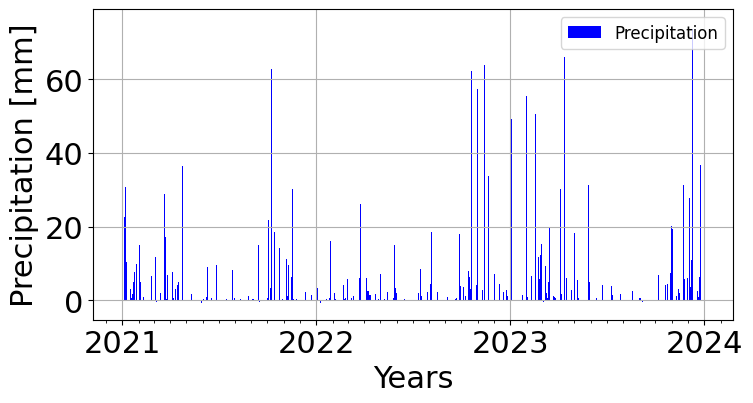

In [55]:
fig = plt.figure(figsize=(8, 4.5))
ax = fig.add_subplot(111)

ax.bar(ti_fechas, Pi*1000, color='blue', label='Precipitation')
ax.set_xlabel('Years')
ax.set_ylabel('Precipitation [mm]')
ax.legend(loc='upper right', fontsize="12")
format_year_axis(ax)

plt.tight_layout()
plt.grid()
plt.show()

# Grafico de $\epsilon$

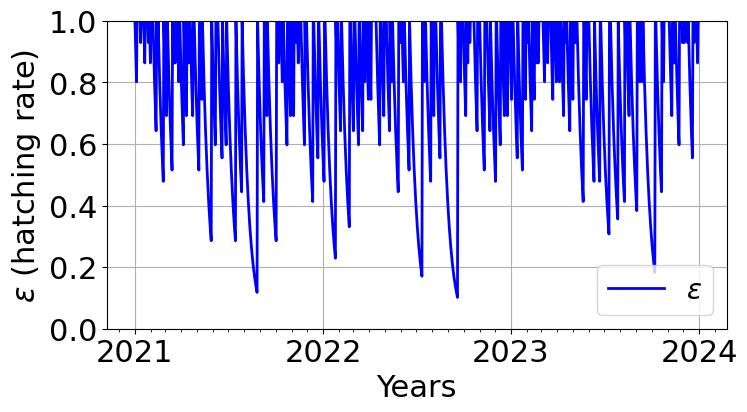

In [56]:
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)

ax.plot(ti_fechas, epsilon, 'blue', lw=2, label=r'$\epsilon$')
ax.set(ylim=(0, 1))
ax.set_xlabel('Years')
ax.set_ylabel(r'$\epsilon$ (hatching rate)')
ax.legend(loc='lower right', fontsize="20")
format_year_axis(ax)

plt.grid()
plt.show()

# Grafico de temperatura

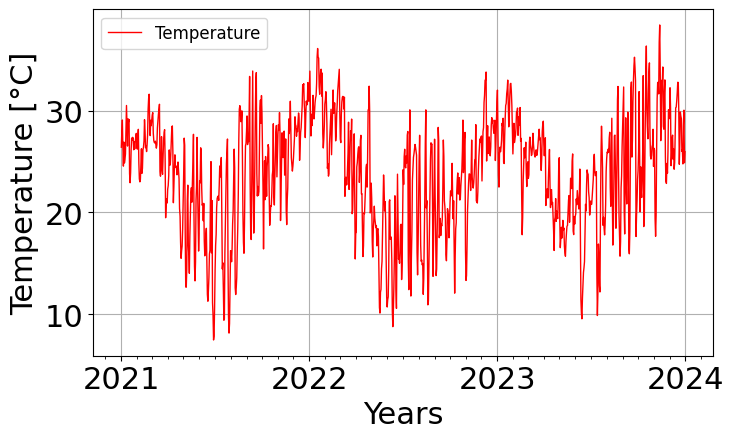

In [57]:
fig = plt.figure(figsize=(8, 4.5))
ax = fig.add_subplot(111)

ax.plot(ti_fechas, tempi, color='red', lw=1, label='Temperature')
ax.set_xlabel('Years')
ax.set_ylabel('Temperature [°C]')
ax.legend(loc='upper left', fontsize="12")
format_year_axis(ax)

plt.grid()
plt.show()

# Grafico de $Q_0$

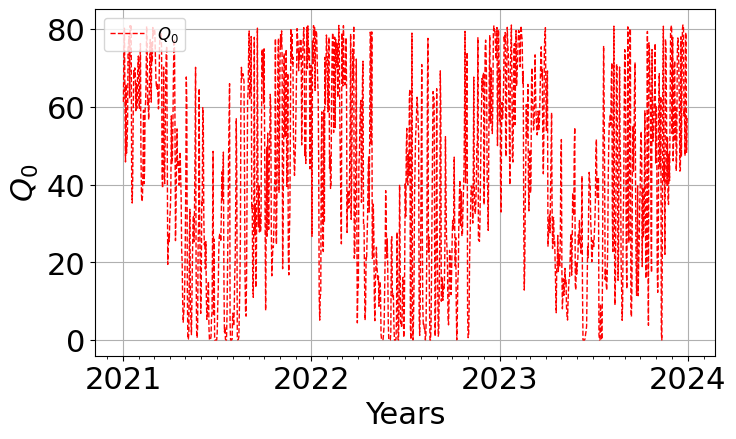

In [58]:
fig = plt.figure(figsize=(8, 4.5))
ax = fig.add_subplot(111)

ax.plot(ti_fechas, Q_0, 'red', lw=1, label='$Q_0$', linestyle='--')
ax.set_xlabel('Years')
ax.set_ylabel('$Q_0$')
ax.legend(loc='upper left', fontsize="12")
format_year_axis(ax)

plt.grid()
plt.show()

# Grafico de la poblacion de mosquitos

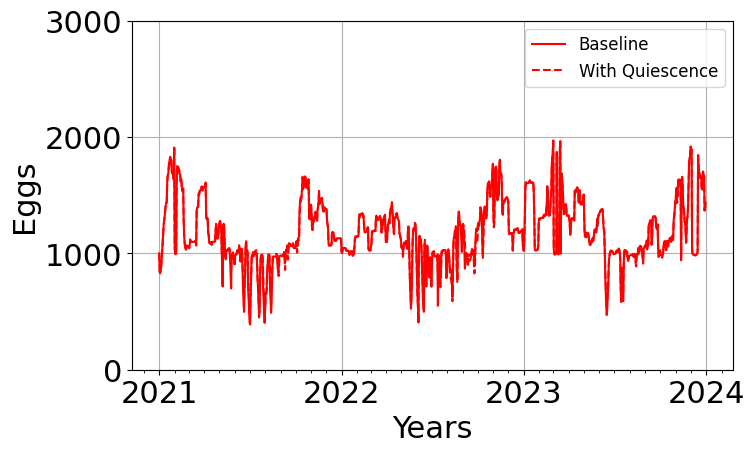

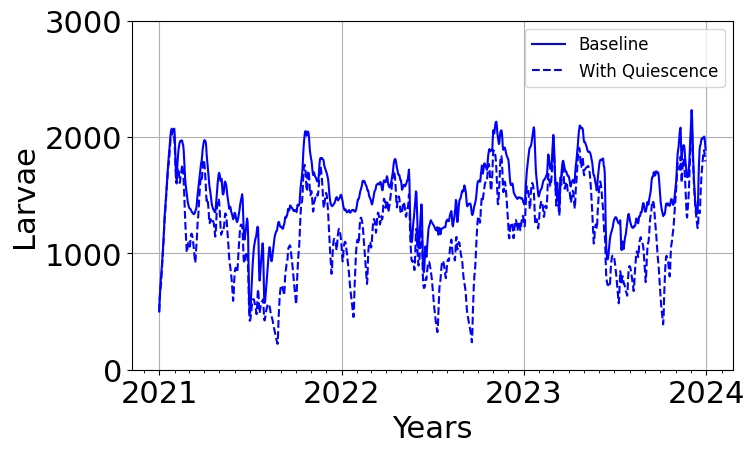

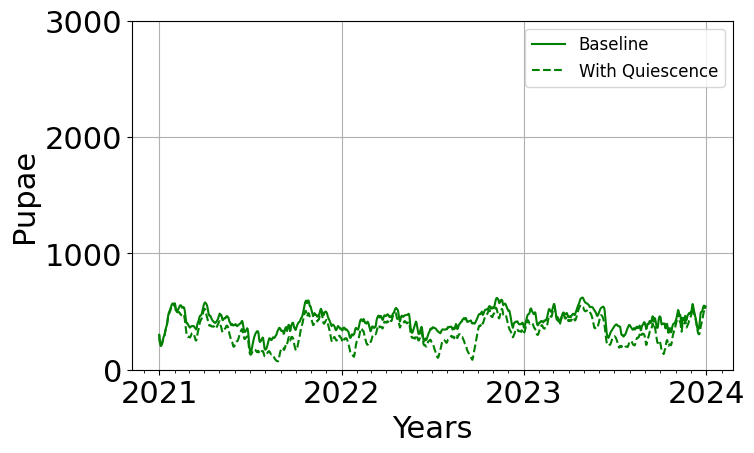

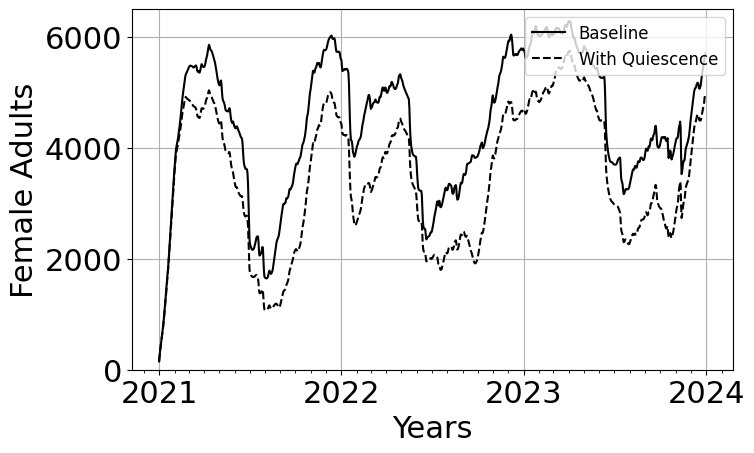

In [59]:
# Variable, etiqueta, color y limite del eje y
poblaciones = [('E', 'Eggs', 'red', 3000),
               ('L', 'Larvae', 'blue', 3000),
               ('P', 'Pupae', 'green', 3000),
               ('A', 'Female Adults', 'black', 6500)]

for key, label, color, ymax in poblaciones:
  plt.figure(figsize=(8, 5))
  plt.plot(ti_fechas, pop_base[key], color=color, linestyle='-', label='Baseline')
  plt.plot(ti_fechas, pop_quiescence[key], color=color, linestyle='--', label='With Quiescence')
  plt.xlabel('Years')
  plt.ylabel(label)
  plt.grid(True)
  plt.ylim([0, ymax])
  plt.legend(loc='upper right', fontsize="12")
  format_year_axis(plt.gca())

  plt.tight_layout()
  plt.show()

# Grafico de la diferencia relativa

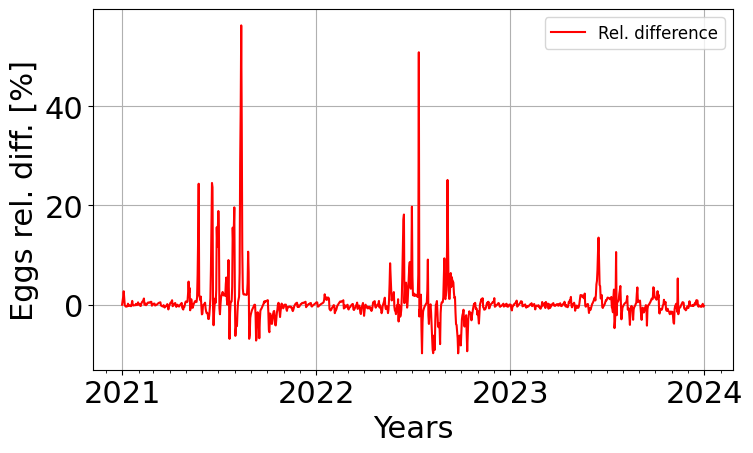

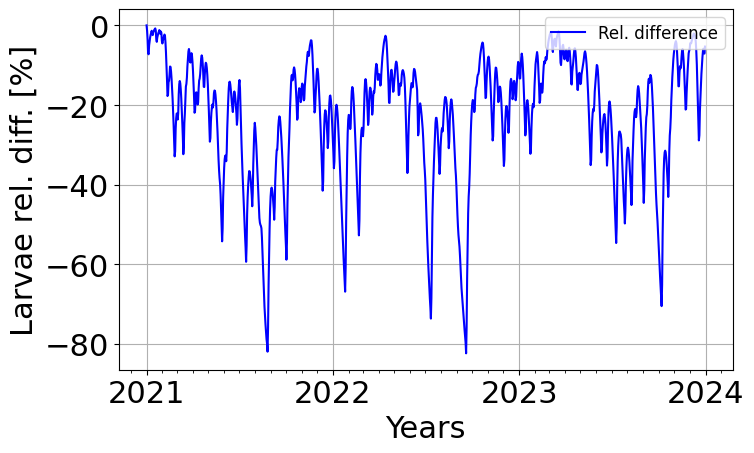

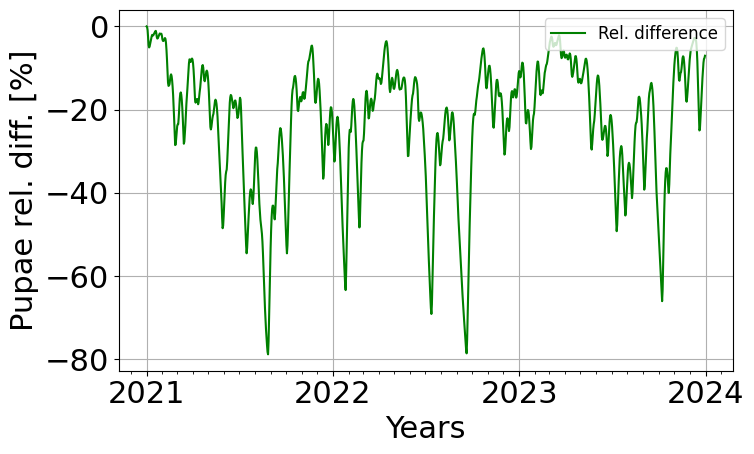

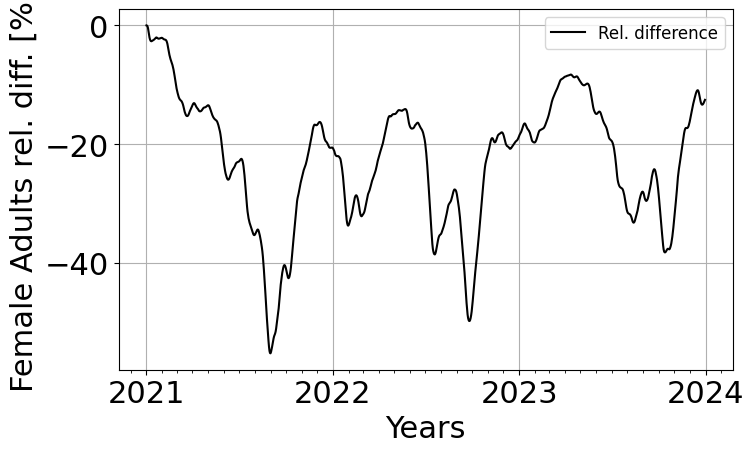

In [60]:
for key, label, color, ymax in poblaciones:
  dif = 100*(pop_quiescence[key] - pop_base[key])/pop_base[key]

  plt.figure(figsize=(8, 5))
  plt.plot(ti_fechas, dif, color=color, linestyle='-', label='Rel. difference')
  plt.xlabel('Years')
  plt.ylabel(label + ' rel. diff. [%]')
  plt.grid(True)
  plt.legend(loc='upper right', fontsize="12")
  format_year_axis(plt.gca())

  plt.tight_layout()
  plt.show()